<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and source details](README.md)

# 01 · What does smoothing do to a published rate step?

A moving average can make a rate series look gradual even when the published values change in steps. We will fetch the Bank of Japan's daily **Basic Discount Rate and Basic Loan Rate** for 2024, preserve its units and timestamps, and compare it with a deliberately constructed trailing calendar-day average.

This notebook uses **live public BOJ data through the real worker**. The data are materialized once per run, with no synthetic fallback. The average is our descriptive transformation; it is not a separately published BOJ rate or a forecast.

## Choose a trailing calendar-day window

`WINDOW_DAYS` includes the current day and the preceding `WINDOW_DAYS − 1` calendar days. Values from 2 to 30 are supported here. A mean is shown only when all days in the window have observed nonmissing values. Initial incomplete windows and gaps remain unavailable; nothing is forward-filled.

The experiment changes only **5 → 20 days**. Predict a longer transition in the mean after a source step, with unchanged underlying observations. Restart the kernel and Run All after editing.

In [1]:
WINDOW_DAYS = 5  # Integer 2–30 calendar days, including current day; experiment: 20

In [2]:
import hashlib
import json
import os
from datetime import datetime, timezone

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(WINDOW_DAYS,int) and not isinstance(WINDOW_DAYS,bool) and 2 <= WINDOW_DAYS <= 30
WINDOW_PRECEDING=WINDOW_DAYS-1
os.environ["BOJ_API_BASE_URL"]="https://www.stat-search.boj.or.jp/api/v1"
os.environ.pop("BOJ_ALLOW_INSECURE_HTTP",None)
os.environ.pop("VGI_BEARER_TOKENS",None)
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: Bank of Japan IR01/MADR1Z@D · daily 2024 · retrieved {retrieved_at[:10]} UTC · average calculated here",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.05,1,.96));plt.show()
con=haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-boj/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-boj/notebooks/pyproject.toml.

## Attach the portable release and discover the database

The literal command installs the tagged worker through uv's cache; it does not use a local checkout. Its SDK and RPC pins match the release's tested runtime. The official API is public and needs no API key.

The worker's curated database list is a starting point, not an exhaustive catalog. We use `IR01` and series code `MADR1Z@D`. The [official API manual](https://www.stat-search.boj.or.jp/info/api_manual_en.pdf) defines database codes, daily frequency and native date conventions. Source attribution: **Bank of Japan**; the Bank does not guarantee this notebook's content.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'boj' AS boj (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-boj@v0.1.0 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 vgi-boj-worker'
);

,Success


In [4]:
%%sql database_info <<
SELECT database,name,source_url FROM boj.main.datasets(query := 'IR01');

In [5]:
display(database_info)

,database,name,source_url
0,IR01,Basic Discount Rates and Basic Loan Rates,https://www.stat-search.boj.or.jp/info/api_man...


## Bound the request, then inspect the returned metadata

For **daily** BOJ series, request bounds still use `YYYYMM`. `202401` through `202412` includes January through December 2024. Returned daily period codes use `YYYYMMDD`. These are observation-date labels, not publication instants; the response's `source_timestamp` retains its source timezone.

`max_rows := 0` requests all matching pages. A positive row cap would intentionally truncate output, so it is unsuitable for checking complete calendar coverage. The one-code selection and closed month interval bound the request.

In [6]:
request_started=datetime.now(timezone.utc).isoformat()

In [7]:
%%sql
CREATE TABLE source_observations AS
SELECT * FROM boj.main.observations(
    'IR01',['MADR1Z@D'],start_period := '202401',end_period := '202412',
    language := 'en',max_rows := 0
);

,Count


In [8]:
retrieved_at=datetime.now(timezone.utc).isoformat()

In [9]:
%%sql source_metadata <<
SELECT DISTINCT database,series_code,name,unit,frequency,category,last_update,
                start_period,end_period,notes,source_timestamp
FROM source_observations ORDER BY series_code;

In [10]:
display(source_metadata)
assert len(source_metadata)==1, "Expected one consistent series metadata record"
m=source_metadata.iloc[0]
assert m.series_code=="MADR1Z@D" and m.frequency=="DAILY"
assert m.unit=="Percent per annum", "Review unit conversion before continuing"
prose(f"**{m['name']}** is returned in **{m.unit}**, at **{m.frequency}** frequency. "
      f"**Retrieval interval:** {request_started} to {retrieved_at}. **Source timestamp:** {m.source_timestamp}. "
      f"**Source last-update date:** {m.last_update}. These current metadata fields do not reconstruct historical release vintages. "
      "The original value strings remain in the materialized source table.")

,database,series_code,name,unit,frequency,category,last_update,start_period,end_period,notes,source_timestamp
0,IR01,MADR1Z@D,The Basic Discount Rate and Basic Loan Rate,Percent per annum,DAILY,The Basic Discount Rates and Basic Loan Rates,2026-11-13,None,None,None,2026-11-14T14:35:42.583+09:00


**The Basic Discount Rate and Basic Loan Rate** is returned in **Percent per annum**, at **DAILY** frequency. **Retrieval interval:** 2026-11-14T05:35:41.663936+00:00 to 2026-11-14T05:35:42.771822+00:00. **Source timestamp:** 2026-11-14T14:35:42.583+09:00. **Source last-update date:** 2026-11-13 00:00:00. These current metadata fields do not reconstruct historical release vintages. The original value strings remain in the materialized source table.

## Validate dates and construct the daily calendar

Only after verifying `DAILY` frequency do we parse `YYYYMMDD` into dates. The complete 2024 calendar includes leap day. A left join distinguishes an absent source row from a present row with a missing value. Neither becomes zero.

The source fingerprint below includes native periods and original value text, but excludes the response-generation timestamp so repeated retrievals can compare the observations themselves.

In [11]:
%%sql
CREATE TABLE parsed AS
SELECT *,try_strptime(period,'%Y%m%d')::DATE AS observation_date
FROM source_observations;
CREATE TABLE daily AS
SELECT d.calendar_date::DATE AS observation_date,p.value,p.value_text,
       p.period IS NOT NULL AS source_row_present
FROM generate_series(DATE '2024-01-01',DATE '2024-12-31',INTERVAL '1 day') d(calendar_date)
LEFT JOIN parsed p ON p.observation_date=d.calendar_date;

,Count


In [12]:
%%sql availability <<
SELECT (SELECT count(*) FROM parsed) AS source_rows,
       (SELECT count(DISTINCT period) FROM parsed) AS unique_periods,
       (SELECT count(*) FROM parsed WHERE observation_date IS NULL OR observation_date NOT BETWEEN DATE '2024-01-01' AND DATE '2024-12-31') AS invalid_dates,
       count(*) AS calendar_days,
       count(*) FILTER (WHERE NOT source_row_present) AS absent_days,
       count(*) FILTER (WHERE source_row_present AND value IS NULL) AS missing_source_values,
       count(value) AS observed_days,min(value) AS minimum_rate,max(value) AS maximum_rate
FROM daily;

In [13]:
display(availability)
a=availability.iloc[0]
assert a.source_rows==a.unique_periods and a.invalid_dates==0 and a.observed_days>0
assert a.calendar_days==366
source_rows=con.execute("SELECT series_code,period,value_text,unit,frequency FROM source_observations ORDER BY period").fetchall()
source_hash=hashlib.sha256(json.dumps(source_rows,separators=(",",":"),ensure_ascii=False).encode()).hexdigest()
prose(f"The source has **{int(a.observed_days)} nonmissing daily values** on a **{int(a.calendar_days)}-day calendar**, "
      f"with **{int(a.absent_days)} absent rows** and **{int(a.missing_source_values)} present-but-missing values**. "
      f"Observed rates span **{a.minimum_rate:.3f}% to {a.maximum_rate:.3f}% per annum**. "
      f"**Observation fingerprint:** `{source_hash}`.")

,source_rows,unique_periods,invalid_dates,calendar_days,absent_days,missing_source_values,observed_days,minimum_rate,maximum_rate
0,366,366,0,366,0,0,366,0.3,0.5


The source has **366 nonmissing daily values** on a **366-day calendar**, with **0 absent rows** and **0 present-but-missing values**. Observed rates span **0.300% to 0.500% per annum**. **Observation fingerprint:** `f52f6d4785aff61d9af0807c4e697e5b62dc89c1ccefe9a3f0cef1bddee56ea2`.

## Identify source changes before smoothing them

The following table compares adjacent calendar days. A change is reported only when both days have observed values. One percentage point equals 100 basis points, so the rate difference is multiplied by 100. A missing previous day is not a zero-rate baseline.

In [14]:
%%sql changes <<
WITH adjacent AS (
    SELECT observation_date,value,lag(value) OVER (ORDER BY observation_date) AS previous_rate
    FROM daily
)
SELECT observation_date,previous_rate,value AS published_rate,
       100*(value-previous_rate) AS change_basis_points
FROM adjacent WHERE previous_rate IS NOT NULL AND value IS NOT NULL AND abs(value-previous_rate)>1e-12
ORDER BY observation_date;

In [15]:
display(changes)
prose(f"There are **{len(changes)} observed day-to-day changes** in this bounded calendar. "
      "Their dates and magnitudes describe this series; the table does not infer announcement timing or economic causes.")

,observation_date,previous_rate,published_rate,change_basis_points
0,2024-08-01,0.3,0.5,20.0


There are **1 observed day-to-day changes** in this bounded calendar. Their dates and magnitudes describe this series; the table does not infer announcement timing or economic causes.

## Require a complete trailing window

The calendar grid lets `ROWS` mean calendar days. SQL counts nonmissing values in each window, and emits a mean only when that count equals `WINDOW_DAYS`. The first incomplete windows remain NULL. This mean weights each included calendar day equally; it is not a market-volume-weighted rate.

A useful check is that every available mean lies between its window's smallest and largest published values.

In [16]:
%%sql
CREATE TABLE window_stats AS
SELECT *,count(value) OVER w AS available_in_window,
       avg(value) OVER w AS raw_average,min(value) OVER w AS window_min,max(value) OVER w AS window_max
FROM daily
WINDOW w AS (ORDER BY observation_date ROWS BETWEEN {{WINDOW_PRECEDING}} PRECEDING AND CURRENT ROW);
CREATE TABLE smoothed AS
SELECT *,CASE WHEN available_in_window={{WINDOW_DAYS}} THEN raw_average END AS trailing_average
FROM window_stats;

,Count


In [17]:
%%sql curves <<
SELECT observation_date,value,trailing_average,
       100*(value-trailing_average) AS published_minus_average_bp,
       window_min,window_max
FROM smoothed ORDER BY observation_date;

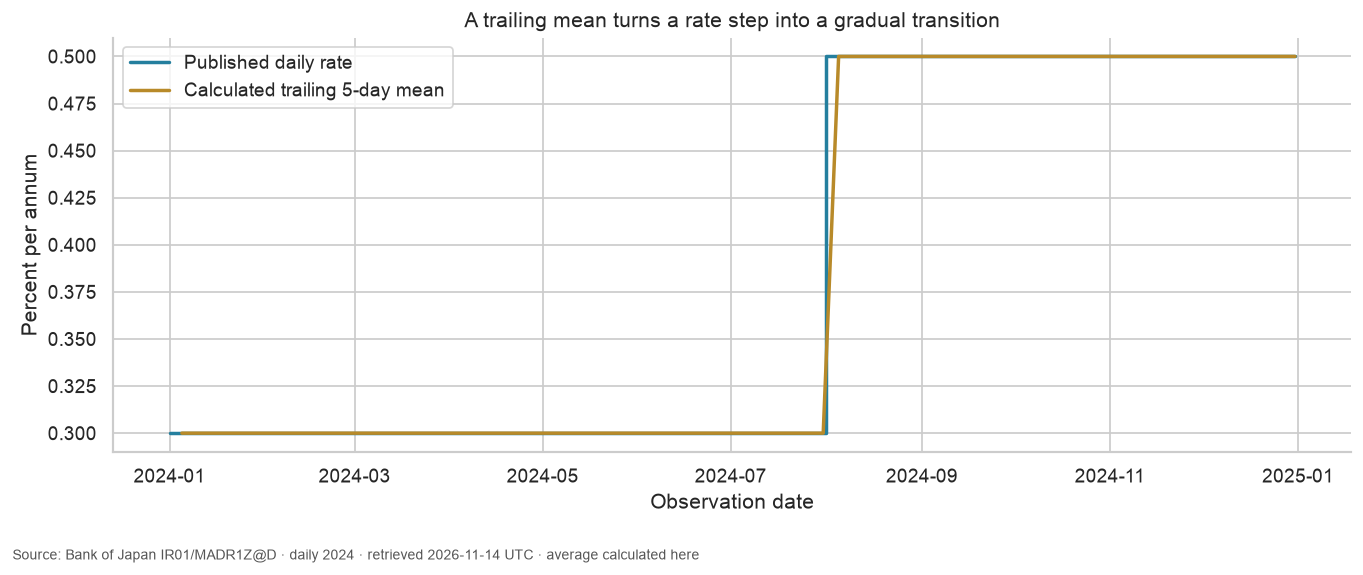

In [18]:
available=curves.dropna(subset=["trailing_average"])
assert len(available)>0
assert ((available.trailing_average>=available.window_min-1e-12)&(available.trailing_average<=available.window_max+1e-12)).all()
fig,ax=plt.subplots(figsize=(11,4.8))
ax.plot(curves.observation_date,curves.value,drawstyle="steps-post",color="#247f9e",label="Published daily rate",linewidth=2)
ax.plot(curves.observation_date,curves.trailing_average,color="#b88a29",label=f"Calculated trailing {WINDOW_DAYS}-day mean",linewidth=2)
ax.set(xlabel="Observation date",ylabel="Percent per annum",title="A trailing mean turns a rate step into a gradual transition")
ax.legend(loc="upper left");finish(fig)

## Measure the temporary difference

Subtract the calculated mean from the published daily rate, then express the difference in basis points. Positive values mean the published rate is above its trailing mean; negative values mean it is below. The mean can take intermediate values that never appeared as a published daily rate in this window.

The chart zooms to 30 calendar days on either side of the last observed source change. Both experiment runs use that same source-based time window and vertical scale.

In [19]:
%%sql summary <<
SELECT count(*) FILTER (WHERE trailing_average IS NOT NULL) AS complete_windows,
       count(*) FILTER (WHERE trailing_average IS NULL) AS unavailable_windows,
       count(*) FILTER (WHERE trailing_average IS NOT NULL AND abs(value-trailing_average)>1e-12) AS differing_days,
       max(abs(100*(value-trailing_average))) AS maximum_gap_bp,
       count(*) FILTER (WHERE trailing_average IS NOT NULL AND NOT EXISTS (
           SELECT 1 FROM daily d WHERE abs(d.value-s.trailing_average)<1e-12
       )) AS intermediate_mean_days
FROM smoothed s;

,complete_windows,unavailable_windows,differing_days,maximum_gap_bp,intermediate_mean_days
0,362,4,4,16.0,4


/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_38270/3332437388.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  xlim=(focus-pd.Timedelta(days=30),focus+pd.Timedelta(days=30)),


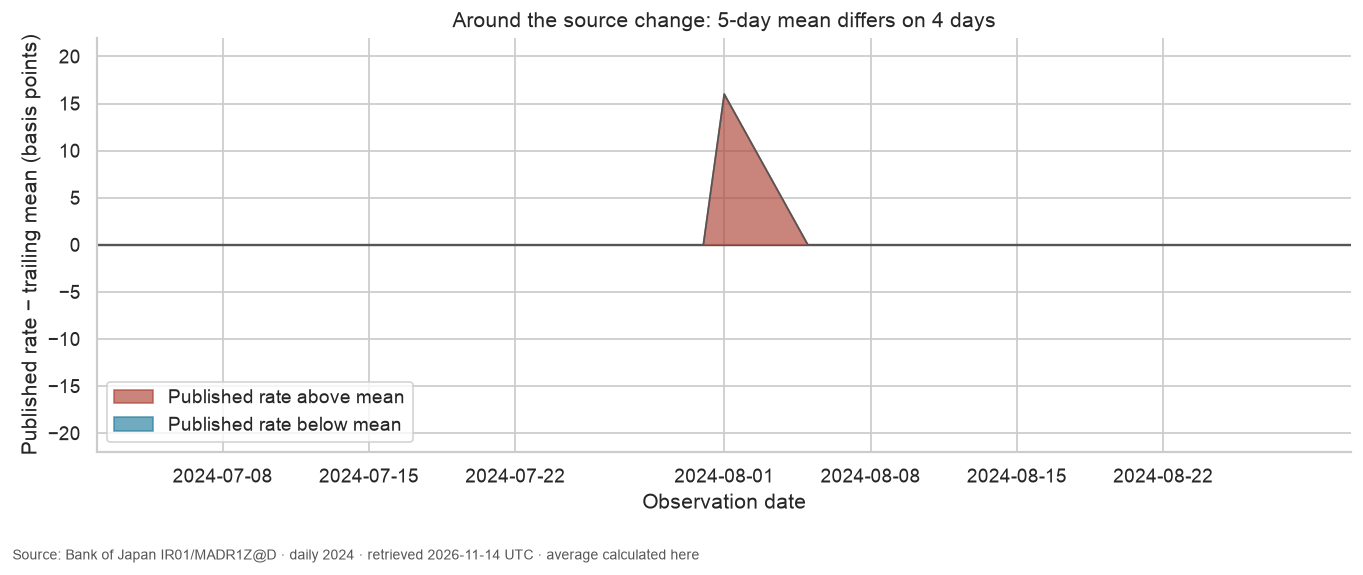

With a **5-day window**, **362 means** are available and **4 windows** remain unavailable. The mean differs from the published value on **4 days**, with a maximum absolute gap of **16.00 basis points**. On **4 days**, the calculated mean is not equal to any published daily value in this source window. Those intermediate levels belong to the transformation, not the original series.

In [20]:
display(summary)
s=summary.iloc[0]
gap=curves.published_minus_average_bp
fig,ax=plt.subplots(figsize=(11,4.8))
ax.plot(curves.observation_date,gap,color="#555555",linewidth=1)
ax.fill_between(curves.observation_date,gap,0,where=gap>=0,color="#ad4336",alpha=.65,label="Published rate above mean")
ax.fill_between(curves.observation_date,gap,0,where=gap<0,color="#247f9e",alpha=.65,label="Published rate below mean")
ax.axhline(0,color="#555555",linewidth=.8)
span=max(float(changes.change_basis_points.abs().max())*1.1,1) if len(changes) else 1
focus=changes.observation_date.iloc[-1] if len(changes) else curves.observation_date.iloc[-1]
ax.set(xlabel="Observation date",ylabel="Published rate − trailing mean (basis points)",ylim=(-span,span),
       xlim=(focus-pd.Timedelta(days=30),focus+pd.Timedelta(days=30)),
       title=f"Around the source change: {WINDOW_DAYS}-day mean differs on {int(s.differing_days)} days")
ax.legend(loc="lower left");finish(fig)
prose(f"With a **{WINDOW_DAYS}-day window**, **{int(s.complete_windows)} means** are available and "
      f"**{int(s.unavailable_windows)} windows** remain unavailable. The mean differs from the published value on "
      f"**{int(s.differing_days)} days**, with a maximum absolute gap of **{s.maximum_gap_bp:.2f} basis points**. "
      f"On **{int(s.intermediate_mean_days)} days**, the calculated mean is not equal to any published daily value in this source window. "
      "Those intermediate levels belong to the transformation, not the original series.")

## One change to test

Change only **`WINDOW_DAYS` from `5` to `20`** and execute a separate copy. First compare observation fingerprints and availability diagnostics. If the source is unchanged, compare the number of differing days, maximum gap and the width of the transition. The larger window should retain earlier values longer after a step, while also requiring more initial history before its first complete mean.

Restore **5** afterward; the [README](README.md) gives the command. This exercise describes one named historical rate series. It does not estimate market borrowing costs, identify policy causes, reconstruct announcement-time knowledge or forecast future rates.

In [21]:
con.execute("DETACH boj")
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and source details](README.md)